# Assignment 2 — AITU Smart Classroom Energy Stream
Galymzhan Tamirlan BDA-2407

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW_DATA = [
    {"Time": "10:00", "Room": "C1.3.101", "Temp_C": 21.5, "CO2_ppm": 620, "Occupancy": 18, "Power_kW": 3.2},
    {"Time": "10:01", "Room": "C1.3.101", "Temp_C": 21.7, "CO2_ppm": 650, "Occupancy": 20, "Power_kW": 3.4},
    {"Time": "10:02", "Room": "C1.3.101", "Temp_C": None, "CO2_ppm": 690, "Occupancy": 22, "Power_kW": 3.5},
    {"Time": "10:03", "Room": "C1.3.101", "Temp_C": 22.1, "CO2_ppm": 720, "Occupancy": 24, "Power_kW": 3.8},
    {"Time": "10:04", "Room": "C1.3.101", "Temp_C": 22.3, "CO2_ppm": None, "Occupancy": 25, "Power_kW": 4.0},
    {"Time": "10:05", "Room": "C1.3.101", "Temp_C": 22.5, "CO2_ppm": 780, "Occupancy": 27, "Power_kW": 4.2},
    {"Time": "10:06", "Room": "C1.3.101", "Temp_C": 22.6, "CO2_ppm": 810, "Occupancy": 29, "Power_kW": 4.4},
    {"Time": "10:07", "Room": "C1.3.101", "Temp_C": 22.7, "CO2_ppm": 830, "Occupancy": None, "Power_kW": 4.6},
    {"Time": "10:08", "Room": "C1.3.101", "Temp_C": 22.9, "CO2_ppm": 850, "Occupancy": 31, "Power_kW": 4.8},
    {"Time": "10:09", "Room": "C1.3.101", "Temp_C": 23.1, "CO2_ppm": 900, "Occupancy": 33, "Power_kW": 5.1},
    {"Time": "10:10", "Room": "C1.3.101", "Temp_C": 23.2, "CO2_ppm": 920, "Occupancy": 35, "Power_kW": 5.4},
    {"Time": "10:11", "Room": "C1.3.101", "Temp_C": 23.3, "CO2_ppm": 950, "Occupancy": 37, "Power_kW": 5.7},
]

df = pd.DataFrame(RAW_DATA)
df["Time"] = pd.to_datetime(df["Time"], format="%H:%M")
df.isna().sum()

Time         0
Room         0
Temp_C       1
CO2_ppm      1
Occupancy    1
Power_kW     0
dtype: int64

## Part A — Cleaning

In [2]:
clean = df.copy()
clean["Temp_C"] = clean["Temp_C"].interpolate(method="linear")
clean["CO2_ppm"] = clean["CO2_ppm"].interpolate(method="linear")
clean["Occupancy"] = clean["Occupancy"].ffill().astype(int)
clean[["Time", "Temp_C", "CO2_ppm", "Occupancy", "Power_kW"]]

                  Time  Temp_C  CO2_ppm  Occupancy  Power_kW
0  1900-01-01 10:00:00    21.5    620.0         18       3.2
1  1900-01-01 10:01:00    21.7    650.0         20       3.4
2  1900-01-01 10:02:00    21.9    690.0         22       3.5
3  1900-01-01 10:03:00    22.1    720.0         24       3.8
4  1900-01-01 10:04:00    22.3    750.0         25       4.0
5  1900-01-01 10:05:00    22.5    780.0         27       4.2
6  1900-01-01 10:06:00    22.6    810.0         29       4.4
7  1900-01-01 10:07:00    22.7    830.0         29       4.6
8  1900-01-01 10:08:00    22.9    850.0         31       4.8
9  1900-01-01 10:09:00    23.1    900.0         33       5.1
10 1900-01-01 10:10:00    23.2    920.0         35       5.4
11 1900-01-01 10:11:00    23.3    950.0         37       5.7

## Part B — 3-min Rolling Mean

In [3]:
roll = clean.copy()
roll["Temp_roll"] = roll["Temp_C"].rolling(3).mean()
roll["CO2_roll"] = roll["CO2_ppm"].rolling(3).mean()
roll["Power_roll"] = roll["Power_kW"].rolling(3).mean()
roll[["Time", "Temp_roll", "CO2_roll", "Power_roll"]].dropna()

                  Time  Temp_roll    CO2_roll  Power_roll
2  1900-01-01 10:02:00  21.700000  653.333333    3.366667
3  1900-01-01 10:03:00  21.900000  686.666667    3.566667
4  1900-01-01 10:04:00  22.100000  720.000000    3.766667
5  1900-01-01 10:05:00  22.300000  750.000000    4.000000
6  1900-01-01 10:06:00  22.466667  780.000000    4.200000
7  1900-01-01 10:07:00  22.600000  806.666667    4.400000
8  1900-01-01 10:08:00  22.733333  830.000000    4.600000
9  1900-01-01 10:09:00  22.900000  860.000000    4.833333
10 1900-01-01 10:10:00  23.066667  890.000000    5.100000
11 1900-01-01 10:11:00  23.200000  923.333333    5.400000

## Part C — Feature Engineering

In [4]:
feat = clean.copy()
feat["occupancy_density"] = feat["Occupancy"] / 40
feat["energy_per_student"] = feat["Power_kW"] / feat["Occupancy"]
feat["comfort_flag"] = (feat["CO2_ppm"] <= 1000) & feat["Temp_C"].between(20, 24)
feat[["Time", "occupancy_density", "energy_per_student", "comfort_flag"]]

                  Time  occupancy_density  energy_per_student  comfort_flag
0  1900-01-01 10:00:00              0.450            0.177778          True
1  1900-01-01 10:01:00              0.500            0.170000          True
2  1900-01-01 10:02:00              0.550            0.159091          True
3  1900-01-01 10:03:00              0.600            0.158333          True
4  1900-01-01 10:04:00              0.625            0.160000          True
5  1900-01-01 10:05:00              0.675            0.155556          True
6  1900-01-01 10:06:00              0.725            0.151724          True
7  1900-01-01 10:07:00              0.725            0.158621          True
8  1900-01-01 10:08:00              0.775            0.154839          True
9  1900-01-01 10:09:00              0.825            0.154545          True
10 1900-01-01 10:10:00              0.875            0.154286          True
11 1900-01-01 10:11:00              0.925            0.154054          True

## Part D — Statistics

In [5]:
stats = {
    "temp_mean": round(clean["Temp_C"].mean(), 2),
    "temp_median": round(clean["Temp_C"].median(), 2),
    "temp_min": clean["Temp_C"].min(),
    "temp_max": clean["Temp_C"].max(),
    "co2_mean": round(clean["CO2_ppm"].mean(), 2),
    "co2_max": clean["CO2_ppm"].max(),
    "peak_power_time": clean.loc[clean["Power_kW"].idxmax(), "Time"].strftime("%H:%M"),
    "peak_power_kw": clean["Power_kW"].max(),
    "occupancy_power_corr": round(np.corrcoef(clean["Occupancy"], clean["Power_kW"])[0, 1], 4),
}
stats

{'temp_mean': np.float64(22.48), 'temp_median': np.float64(22.55), 'temp_min': np.float64(21.5), 'temp_max': np.float64(23.3), 'co2_mean': np.float64(789.17), 'co2_max': np.float64(950.0), 'peak_power_time': '10:11', 'peak_power_kw': np.float64(5.7), 'occupancy_power_corr': np.float64(0.9946)}

## Part E — Plots

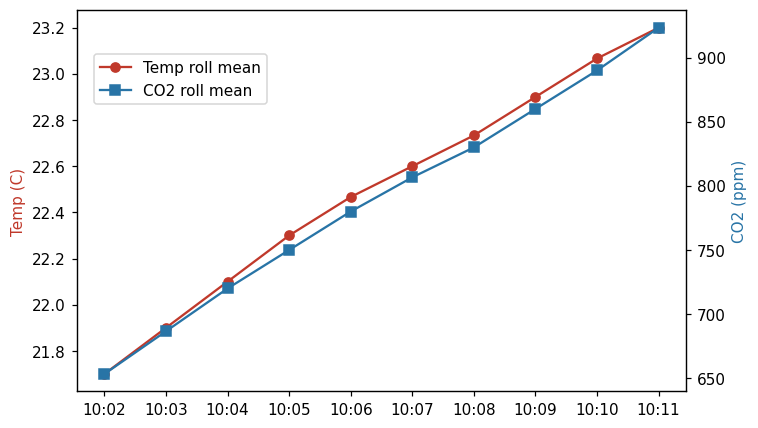

In [6]:
times = clean["Time"].dt.strftime("%H:%M")
fig, ax1 = plt.subplots(figsize=(7, 4))
ax2 = ax1.twinx()
ax1.plot(times, roll["Temp_roll"], "o-", color="#c0392b", label="Temp roll mean")
ax2.plot(times, roll["CO2_roll"], "s-", color="#2874a6", label="CO2 roll mean")
ax1.set_ylabel("Temp (C)", color="#c0392b")
ax2.set_ylabel("CO2 (ppm)", color="#2874a6")
plt.xticks(rotation=45)
fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.88))
fig.tight_layout()
plt.show()

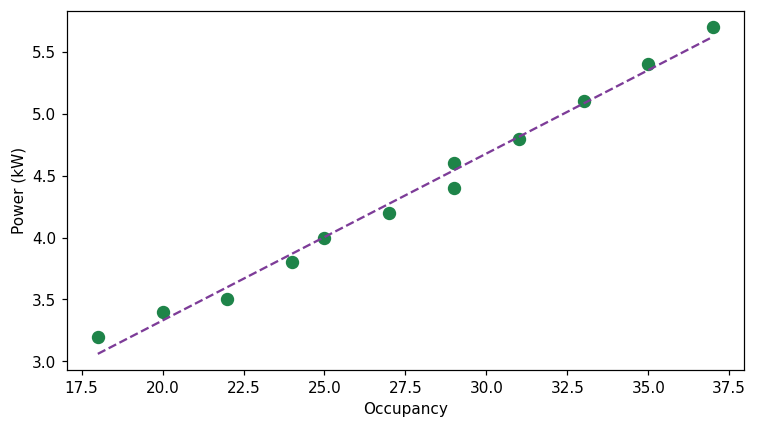

In [7]:
fig2, ax = plt.subplots(figsize=(7, 4))
ax.scatter(clean["Occupancy"], clean["Power_kW"], color="#1e8449", s=60)
z = np.polyfit(clean["Occupancy"], clean["Power_kW"], 1)
ax.plot(clean["Occupancy"], z[0] * clean["Occupancy"] + z[1], "--", color="#7d3c98")
ax.set_xlabel("Occupancy")
ax.set_ylabel("Power (kW)")
fig2.tight_layout()
plt.show()

## Validation check (student-designed)

In [8]:
assert clean.isna().sum().sum() == 0
assert (feat["occupancy_density"] <= 1).all()
assert roll["Temp_roll"].iloc[2] == round((21.5 + 21.7 + 21.9) / 3, 4) or abs(roll["Temp_roll"].iloc[2] - 21.7) < 1e-6
"all checks passed"

'all checks passed'

In [9]:
clean.to_csv("cleaned_classroom_data.csv", index=False,
             date_format="%H:%M")
"saved cleaned_classroom_data.csv"

'saved cleaned_classroom_data.csv'